# 00 · Meet Mario

Greenstone, from Python: boot Super Mario Bros., hold buttons, watch the bytes move.

`gs.boot("smb1")` gives a console at the first frame of play (the ROM comes from greenstone's `roms2/`).
- `nes.step(buttons, frames=1)` runs frames with buttons held (`gs.RIGHT | gs.A`, …).
- `nes.play(buttons_array, pictures=False)` runs one frame per entry and returns the memory after each, `(frames, 2048)`; add `pictures=True` to get the pictures too.
- `nes.ram`, `nes.peek(addr)`, `nes.poke(addr, value)` read and write memory.
- `nes.picture()` returns the screen; `nes.save()` / `nes.load(state)` keep a moment to come back to.
- `nes.frame` counts the frames since boot.

The bytes the videos use (from greenstone's `src/nes/gym/series/ram.rs`):

| address | what | units |
|---|---|---|
| `0x000E` | player state | `08` = normal play |
| `0x0755` | Mario's position on screen, as the scroll code reads it | pixels from the left edge |
| `0x0057` | horizontal speed | signed, sixteenths of a pixel a frame |
| `0x0775` | how far the screen scrolled this frame | pixels |
| `0x001D` | in the air? | `0` ground, `1` jumping, `2` falling |
| `0x00CE` | height | pixels from the top |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider

import greenstone as gs

PLAY, POSITION, SPEED, SCROLL, FLOAT, Y = 0x000E, 0x0755, 0x0057, 0x0775, 0x001D, 0x00CE


def show(picture, title=None):
    plt.figure(figsize=(4, 3.75))
    plt.imshow(picture)
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def held(*parts):
    """A button track from (buttons, frames) pairs: held(gs.RIGHT, 60, gs.RIGHT | gs.A, 20)."""
    return np.concatenate([np.full(n, b, np.uint8) for b, n in zip(parts[::2], parts[1::2])])

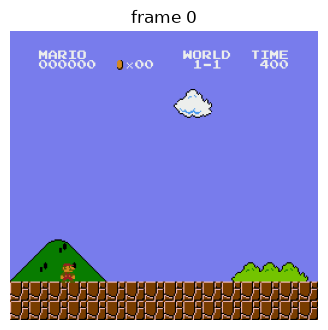

In [2]:
nes = gs.boot("smb1")
show(nes.picture(), f"frame {nes.frame}")

## Hold Right for three seconds

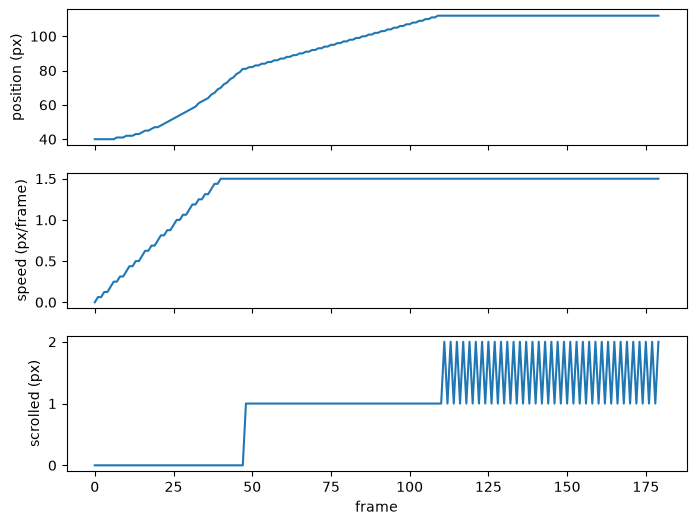

In [3]:
start = nes.save()
ram, pictures = nes.play(held(gs.RIGHT, 180), pictures=True)

fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(ram[:, POSITION]); ax[0].set_ylabel("position (px)")
ax[1].plot(ram[:, SPEED].astype(np.int8) / 16); ax[1].set_ylabel("speed (px/frame)")
ax[2].plot(ram[:, SCROLL]); ax[2].set_ylabel("scrolled (px)")
ax[2].set_xlabel("frame")
plt.show()

Scrub through it: the picture after each frame, beside the bytes.

In [4]:
def look(f):
    r = ram[f]
    show(pictures[f], f"frame {f:03d}: position {r[POSITION]:03d}, speed {np.int8(r[SPEED]) / 16:3.2f}, scrolled {r[SCROLL]:05d}")

interact(look, f=IntSlider(0, 0, len(ram) - 1));

interactive(children=(IntSlider(value=0, description='f', max=179), Output()), _dom_classes=('widget-interact'…

## Play

Some things to find out. `nes.load(start)` puts you back where the run above began.

1. **Running.** Hold `gs.RIGHT | gs.B`. What's Mario's top speed walking, and running? (002 says 1.5 and 2.5 pixels a frame.)
2. **The line.** At what position does the screen start scrolling instead of Mario moving? (002 says 80.)
3. **The lag.** Does the picture show the same moment as the memory? Find the first frame the position byte changes, and the first frame Mario's sprite moves on screen. (The series measured one frame. Hint: compare `pictures[f]` with `pictures[f - 1]`.)
4. **Jumping.** Add `gs.A` partway through. Watch `FLOAT` and `Y`. Does a longer press jump higher?
5. **Poke something.** What happens if you `nes.poke(SPEED, 40)` mid-run?

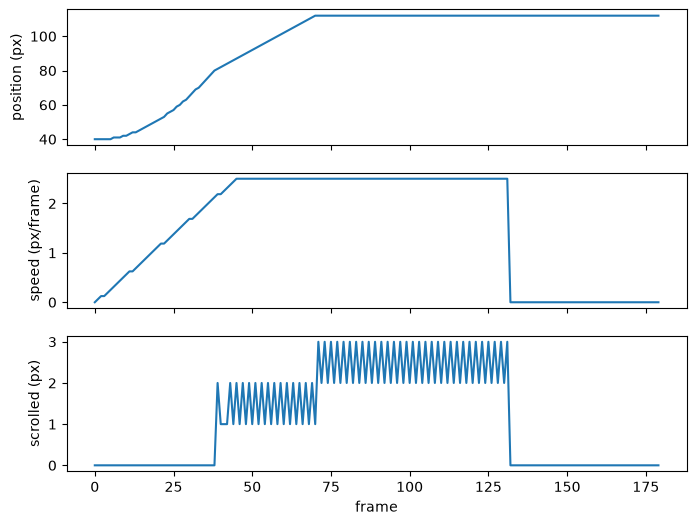

Max speed (Walking): 1.5
Max speed (Running): 2.5


In [5]:
# 1. Running. Hold gs.RIGHT | gs.B. What's Mario's top speed walking, and running? (002 says 1.5 and 2.5 pixels a frame.)
nes.load(start)
ram, pictures = nes.play(held(gs.RIGHT, 180), pictures=True)
walking_max_speed = max([f[SPEED] for f in ram]) / 16

# Reset
nes.load(start)
ram, pictures = nes.play(held(gs.RIGHT | gs.B, 180), pictures=True)
running_max_speed = max([f[SPEED] for f in ram]) / 16
fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(ram[:, POSITION]); ax[0].set_ylabel("position (px)")
ax[1].plot(ram[:, SPEED].astype(np.int8) / 16); ax[1].set_ylabel("speed (px/frame)")
ax[2].plot(ram[:, SCROLL]); ax[2].set_ylabel("scrolled (px)")
ax[2].set_xlabel("frame")
plt.show()
# What's Mario's top speed... walking?
print(f"Max speed (Walking): {walking_max_speed}")
# What's Mario's top speed... running?
print(f"Max speed (Running): {running_max_speed}")

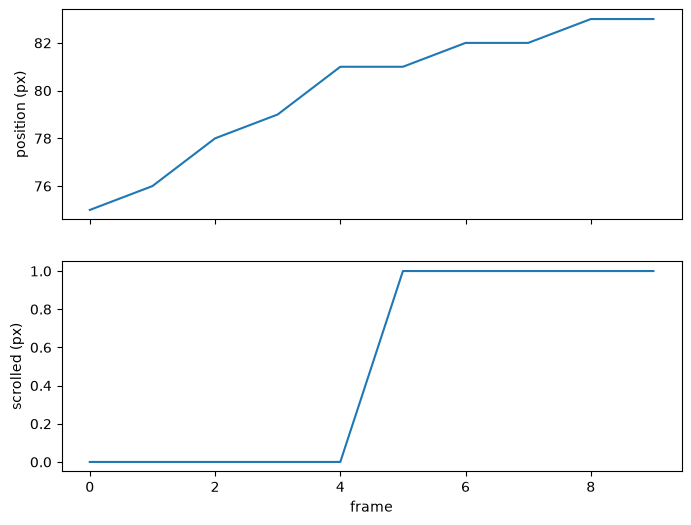

48


In [6]:
# 2. The line. At what position does the screen start scrolling instead of Mario moving? (002 says 80.)
nes.load(start)
ram, pictures = nes.play(held(gs.RIGHT, 180), pictures=True)
first_scroll_frame = [i for i in range(len(ram)) if ram[i][SCROLL] > 0][0]
first_scroll_position = ram[first_scroll_frame][POSITION]

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(ram[first_scroll_frame-5:first_scroll_frame+5, POSITION]); ax[0].set_ylabel("position (px)")
ax[1].plot(ram[first_scroll_frame-5:first_scroll_frame+5, SCROLL]); ax[1].set_ylabel("scrolled (px)")
ax[1].set_xlabel("frame")
plt.show()

# | frame | position | scrolled | notes                                     |
# | ----- | -------- | -------- | ----------------------------------------- |
# | 46    | 79       | 0        |                                           |
# | 47    | 81       | 0        | Mario moved from 79 -> 81, but no scroll. |
# | 48    | 81       | 1        | Mario moved 1px and the screen moved 1px. |
# 
# The code above measures Mario's position at the *end* of the frame, but the
# game decides whether to scroll at the *start* of the frame. So we need to
# do a little peeking and poking.

nes.load(start)
start_frame = first_scroll_frame - 2
start_position = ram[start_frame][POSITION]
nes.step(gs.RIGHT, frames=start_frame)    # walking at full speed, just short of the line (position 79)
moment = nes.save()
has_scrolled = False
number_of_trials = 10

for x in range(number_of_trials):
    nes.step(gs.RIGHT)           # one frame
    if not has_scrolled and nes.peek(SCROLL):
        has_scrolled = True
        actual_first_scroll_frame = start_frame + x
    # print(x, "→ scrolled" if nes.peek(SCROLL) else "→ didn't scroll")

print(actual_first_scroll_frame)

In [10]:
# 3. The lag. Does the picture show the same moment as the memory? Find the 
# first frame the position byte changes, and the first frame Mario's sprite
# moves on screen. (The series measured one frame. Hint: compare pictures[f]
# with pictures[f - 1].)
nes.load(start)
ram, pics = nes.play(held(gs.RIGHT, 10, gs.RIGHT | gs.A, 20, gs.RIGHT, 40), pictures=True)
shoe = (pics == [84, 90, 0]).all(axis=-1)            # Mario's shoe colour
feet = np.array([np.where(s.any(1))[0].max() for s in shoe])

for lag in (0, 1, 2):
    gap = feet[10 + lag:50] - ram[10:50 - lag, Y].astype(int)
    if len(np.unique(gap)) == 1:
        # a lag where the gap is one constant on every frame is the real one
        print(f"lag: {lag} frames, gap: {np.unique(gap)[0]} px")
        break

lag: 1 frames, gap: 32 px


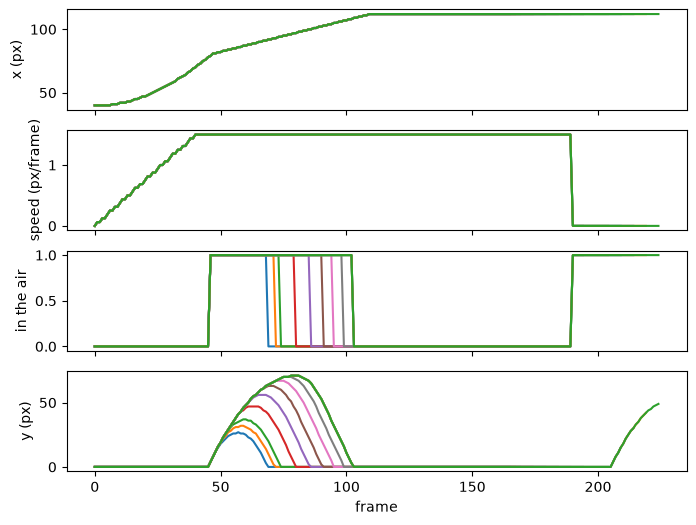

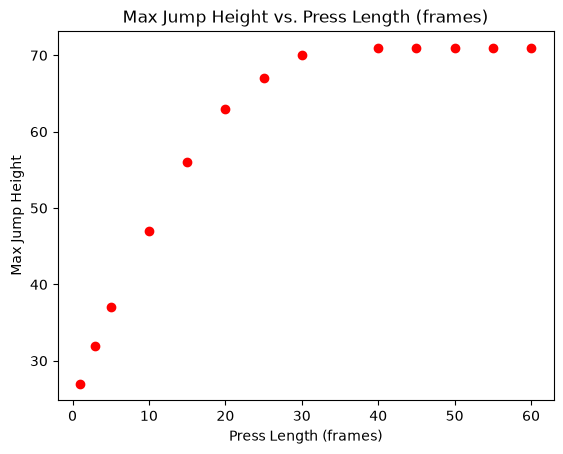

In [20]:
# 4. Jumping. Add gs.A partway through. Watch FLOAT and Y. Does a longer press jump higher?
rams = []
a_lengths = [1, 3, 5, 10, 15, 20, 25, 30, 40, 45, 50, 55, 60]

for a_frames in a_lengths:
    nes.load(start)
    ram = nes.play(held(gs.RIGHT, 45, gs.RIGHT | gs.A, a_frames, gs.RIGHT, 120), pictures=False)  
    rams.append(ram)

ground_y = int(rams[0][0, Y])
fig, ax = plt.subplots(4, 1, figsize=(8, 6), sharex=True)
for i in range(len(rams)):
    ram = rams[i]
    ax[0].plot(ram[:, POSITION]);
    ax[1].plot(ram[:, SPEED].astype(np.int8) / 16);
    ax[2].plot(ram[:, FLOAT]);
    ax[3].plot(ground_y - ram[:, Y]);

ax[0].set_ylabel("x (px)")
ax[1].set_ylabel("speed (px/frame)")
ax[2].set_ylabel("in the air")
ax[3].set_ylabel("y (px)")
ax[3].set_xlabel("frame")
plt.show()

data = [ground_y - ys.min() for ys in [ram[:, Y] for ram in rams]]
fig = plt.plot(a_lengths, data, marker='o', linestyle='', color='red', label='Y')
plt.xlabel('Press Length (frames)')
plt.ylabel('Max Jump Height')
plt.title('Max Jump Height vs. Press Length (frames)')
plt.show()

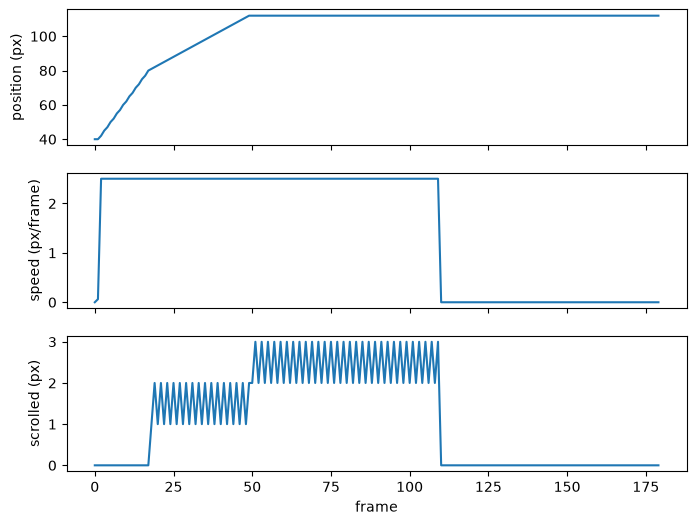

interactive(children=(IntSlider(value=0, description='f', max=179), Output()), _dom_classes=('widget-interact'…

In [21]:
# 5. Poke something. What happens if you nes.poke(SPEED, 40) mid-run?
nes.load(start)
midpoint = 2
length = 180
ram, pictures = nes.play(held(gs.RIGHT | gs.B, midpoint), pictures=True)
nes.poke(SPEED, 140)
ram2, pictures2 = nes.play(held(gs.RIGHT | gs.B, length - midpoint), pictures=True)
ram = np.concatenate((ram, ram2))
pictures = np.concatenate((pictures, pictures2))

fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(ram[:, POSITION]); ax[0].set_ylabel("position (px)")
ax[1].plot(ram[:, SPEED].astype(np.int8) / 16); ax[1].set_ylabel("speed (px/frame)")
ax[2].plot(ram[:, SCROLL]); ax[2].set_ylabel("scrolled (px)")
ax[2].set_xlabel("frame")
plt.show()

interact(look, f=IntSlider(0, 0, len(ram) - 1));